In [1]:
import pandas as pd

df = pd.read_csv("ESD_Dataset.csv")

print(df.columns.tolist())
print(df.shape)
print(df.head())

['U', 'TR', 'IMAX', 'I30', 'I60', 'd', 'D', 'E', 'H', 'Unnamed: 9', 'Unnamed: 10', 'd.1', 'E.1', 'H.1']
(30, 14)
   U    TR  IMAX   I30   I60   d  D     E     H  Unnamed: 9  Unnamed: 10  d.1  \
0  2  0.77  6.95  3.78  2.44  35  A  4.04  2.03         NaN          NaN  d35   
1  2  0.75  7.17  3.69  2.45  65  A  2.36  1.38         NaN          NaN  d65   
2  2  0.76  7.13  3.95  2.50  35  C  3.42  1.64         NaN          NaN  d35   
3  2  0.73  7.28  3.93  2.39  65  C  2.55  0.95         NaN          NaN  d65   
4  2  0.73  7.34  3.67  2.43  35  D  4.08  1.68         NaN          NaN  d35   

    E.1   H.1  
0  4.04  2.03  
1  2.36  1.38  
2  3.42  1.64  
3  2.55  0.95  
4  4.08  1.68  


Preprocessing

In [2]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder

df = pd.read_csv("ESD_Dataset.csv")

print("="*60)
print("Original Dataset")
print("="*60)
print(df.head())

print("\nShape :",df.shape)

df = df.drop(columns=["Unnamed: 9","Unnamed: 10"])

df = df.rename(columns={
    "d":"Distance",
    "D":"Material",
    "E":"Electric_Field",
    "H":"Magnetic_Field"
})

df = df.drop(columns=["d.1","E.1","H.1"])

print("\nColumns After Cleaning")
print(df.columns)

le = LabelEncoder()
df["Material"] = le.fit_transform(df["Material"])

print("\nMissing Values")
print(df.isnull().sum())

print("\nDataset Information")
print(df.info())

print("\nStatistical Summary")
print(df.describe())

df.to_csv("ESD_Cleaned.csv",index=False)

print("\nCleaned dataset saved as ESD_Cleaned.csv")

Original Dataset
   U    TR  IMAX   I30   I60   d  D     E     H  Unnamed: 9  Unnamed: 10  d.1  \
0  2  0.77  6.95  3.78  2.44  35  A  4.04  2.03         NaN          NaN  d35   
1  2  0.75  7.17  3.69  2.45  65  A  2.36  1.38         NaN          NaN  d65   
2  2  0.76  7.13  3.95  2.50  35  C  3.42  1.64         NaN          NaN  d35   
3  2  0.73  7.28  3.93  2.39  65  C  2.55  0.95         NaN          NaN  d65   
4  2  0.73  7.34  3.67  2.43  35  D  4.08  1.68         NaN          NaN  d35   

    E.1   H.1  
0  4.04  2.03  
1  2.36  1.38  
2  3.42  1.64  
3  2.55  0.95  
4  4.08  1.68  

Shape : (30, 14)

Columns After Cleaning
Index(['U', 'TR', 'IMAX', 'I30', 'I60', 'Distance', 'Material',
       'Electric_Field', 'Magnetic_Field'],
      dtype='object')

Missing Values
U                 0
TR                0
IMAX              0
I30               0
I60               0
Distance          0
Material          0
Electric_Field    0
Magnetic_Field    0
dtype: int64

Dataset Informatio

Linear Regression

In [3]:
import pandas as pd

from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
import numpy as np

df=pd.read_csv("ESD_Cleaned.csv")

X=df[["U","TR","IMAX","I30","I60","Distance"]]

y=df["Electric_Field"]

X_train,X_test,y_train,y_test=train_test_split(
X,y,test_size=0.2,random_state=42)

model=LinearRegression()

model.fit(X_train,y_train)

pred=model.predict(X_test)

rmse=np.sqrt(mean_squared_error(y_test,pred))
mae=mean_absolute_error(y_test,pred)
r2=r2_score(y_test,pred)

cv=cross_val_score(model,X,y,cv=5,scoring="r2")

print("="*50)
print("Linear Regression")
print("="*50)

print("RMSE :",rmse)
print("MAE :",mae)
print("R2 :",r2)
print("Cross Validation :",cv.mean())

Linear Regression
RMSE : 2.389985402890215
MAE : 1.9032117412817096
R2 : 0.5813577662087948
Cross Validation : -2.773254970653972


In [4]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

pipe=Pipeline([

("poly",PolynomialFeatures(degree=2)),

("lr",LinearRegression())

])

pipe.fit(X_train,y_train)

pred=pipe.predict(X_test)

rmse=np.sqrt(mean_squared_error(y_test,pred))
mae=mean_absolute_error(y_test,pred)
r2=r2_score(y_test,pred)

print("="*50)
print("Polynomial Regression")
print("="*50)

print("RMSE :",rmse)
print("MAE :",mae)
print("R2 :",r2)

Polynomial Regression
RMSE : 2.851702940637279
MAE : 2.184160850799873
R2 : 0.4039796213098279


In [16]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

param_grid={

"max_depth":[3,5,8,10,15,None],

"min_samples_split":[2,5,10],

"min_samples_leaf":[1,2,4]

}

grid=GridSearchCV(

DecisionTreeRegressor(random_state=42),

param_grid,

cv=5,

scoring="r2"

)

grid.fit(X_train,y_train)

model=grid.best_estimator_

pred=model.predict(X_test)

print("="*50)
print("Decision Tree")
print("="*50)

print("Best Parameters :",grid.best_params_)

print("RMSE :",np.sqrt(mean_squared_error(y_test,pred)))

print("MAE :",mean_absolute_error(y_test,pred))

print("R2 :",r2_score(y_test,pred))

Decision Tree
Best Parameters : {'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
RMSE : 1.0657406814042523
MAE : 0.9392000000000001
R2 : 0.9576132482147458


In [6]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

param_grid={

"max_depth":[3,5,8,10,15,None],

"min_samples_split":[2,5,10],

"min_samples_leaf":[1,2,4]

}

grid=GridSearchCV(

DecisionTreeRegressor(random_state=42),

param_grid,

cv=5,

scoring="r2"

)

grid.fit(X_train,y_train)

model=grid.best_estimator_

pred=model.predict(X_test)

print("="*50)
print("Decision Tree")
print("="*50)

print("Best Parameters :",grid.best_params_)

print("RMSE :",np.sqrt(mean_squared_error(y_test,pred)))

print("MAE :",mean_absolute_error(y_test,pred))

print("R2 :",r2_score(y_test,pred))

Decision Tree
Best Parameters : {'max_depth': 8, 'min_samples_leaf': 1, 'min_samples_split': 2}
RMSE : 0.9528553580335964
MAE : 0.7100000000000001
R2 : 0.9334563677432687


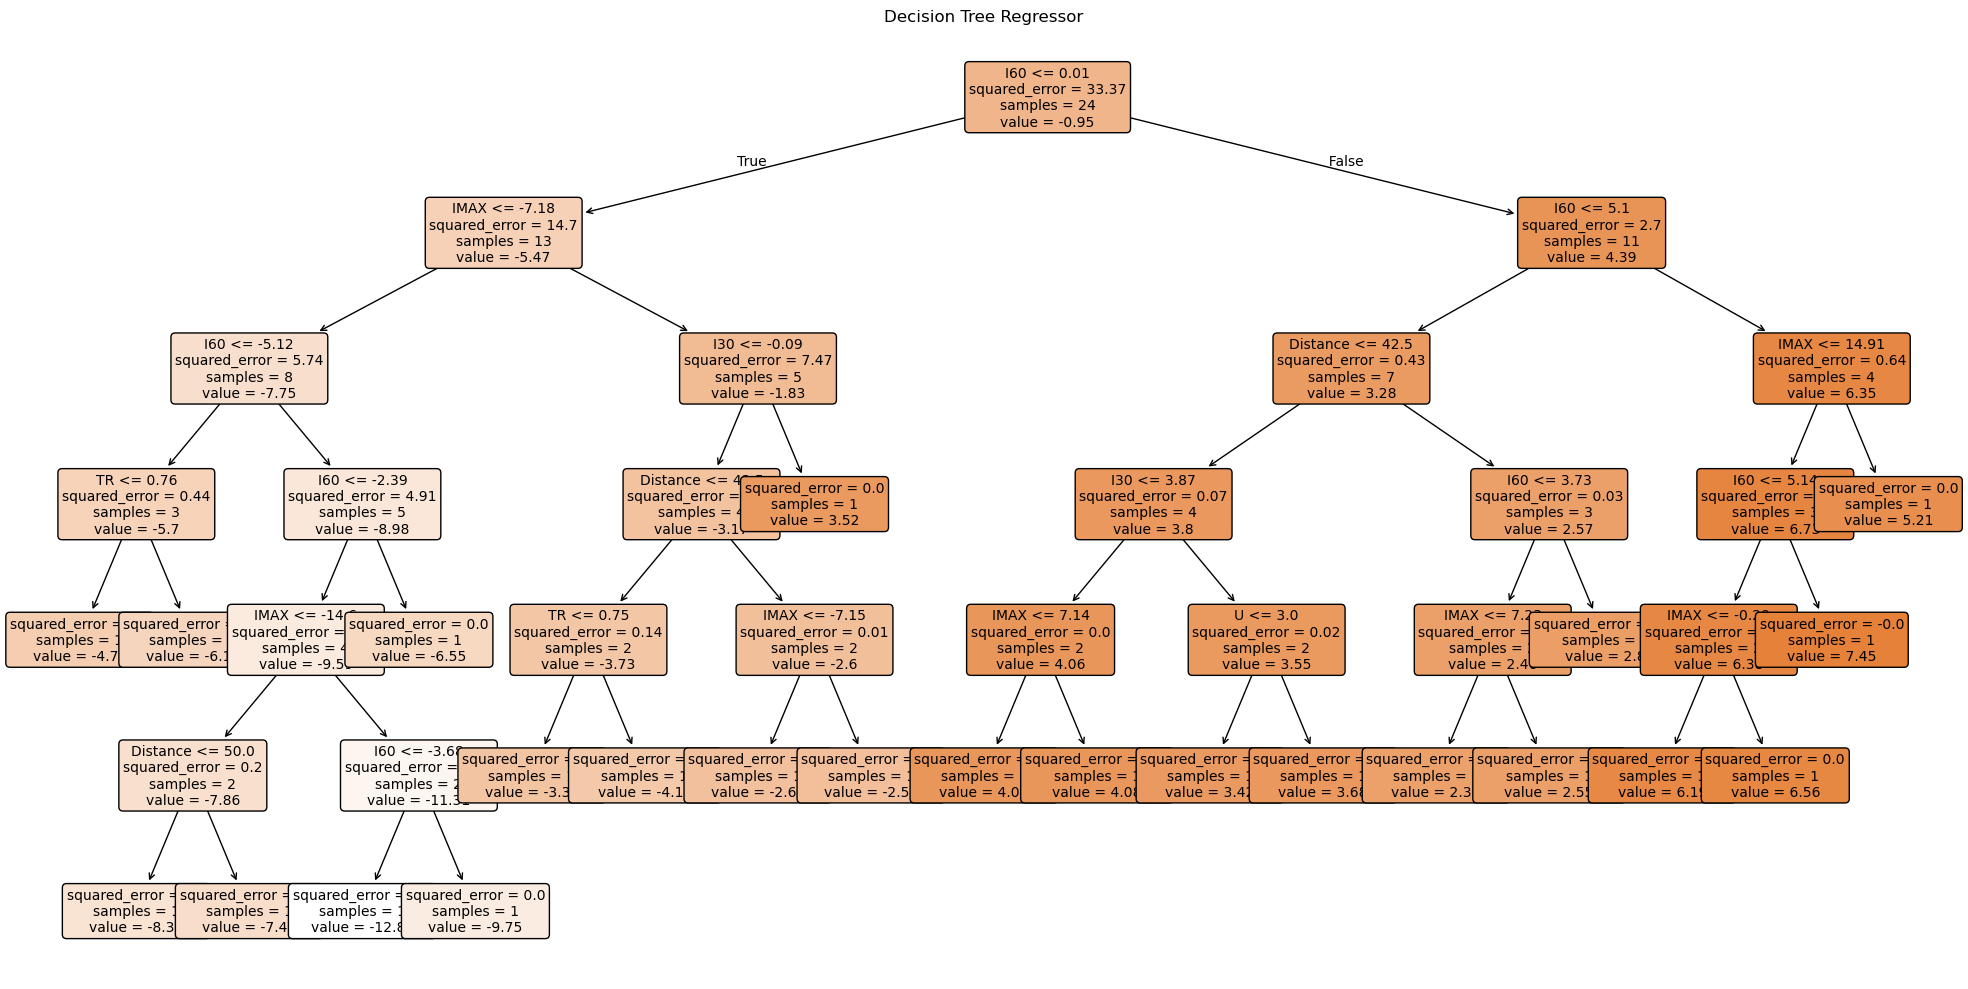

In [7]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20,10))

plot_tree(
    model,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=10,
    precision=2
)

plt.title("Decision Tree Regressor")
plt.tight_layout()
plt.show()

In [8]:
from sklearn.ensemble import RandomForestRegressor

param_grid={

"n_estimators":[50,100,150,200],

"max_depth":[5,10,15,None],

"min_samples_split":[2,5],

"min_samples_leaf":[1,2]

}

grid=GridSearchCV(

RandomForestRegressor(random_state=42),

param_grid,

cv=5,

scoring="r2"

)

grid.fit(X_train,y_train)

model=grid.best_estimator_

pred=model.predict(X_test)

print("="*50)
print("Random Forest")
print("="*50)

print("Best Parameters :",grid.best_params_)

print("RMSE :",np.sqrt(mean_squared_error(y_test,pred)))

print("MAE :",mean_absolute_error(y_test,pred))

print("R2 :",r2_score(y_test,pred))

Random Forest
Best Parameters : {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 150}
RMSE : 1.3746476946637753
MAE : 1.1646444444444406
R2 : 0.8615045970148048


In [9]:
from sklearn.ensemble import ExtraTreesRegressor

param_grid={

"n_estimators":[50,100,150],

"max_depth":[5,10,15,None],

"min_samples_split":[2,5],

"min_samples_leaf":[1,2]

}

grid=GridSearchCV(

ExtraTreesRegressor(random_state=42),

param_grid,

cv=5,

scoring="r2"

)

grid.fit(X_train,y_train)

model=grid.best_estimator_

pred=model.predict(X_test)

print("="*50)
print("Extra Trees")
print("="*50)

print("Best Parameters :",grid.best_params_)

print("RMSE :",np.sqrt(mean_squared_error(y_test,pred)))

print("MAE :",mean_absolute_error(y_test,pred))

print("R2 :",r2_score(y_test,pred))

Extra Trees
Best Parameters : {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 50}
RMSE : 1.2491393060712737
MAE : 1.066558333333333
R2 : 0.8856399620615626


In [10]:
df

,U,TR,IMAX,I30,I60,Distance,Material,Electric_Field,Magnetic_Field
0,2,0.77,6.95,3.78,2.44,35,0,4.04,2.03
1,2,0.75,7.17,3.69,2.45,65,0,2.36,1.38
2,2,0.76,7.13,3.95,2.50,35,1,3.42,1.64
3,2,0.73,7.28,3.93,2.39,65,1,2.55,0.95
4,2,0.73,7.34,3.67,2.43,35,2,4.08,1.68
5,2,0.76,7.16,3.62,-2.40,65,2,3.52,1.12
6,-2,0.75,-7.19,-3.99,-2.41,20,0,-9.75,-2.98
7,-2,0.78,-7.12,-3.80,-2.42,35,0,-4.11,-1.88
8,-2,0.76,-7.13,-3.87,-2.43,50,0,-2.65,-1.75
9,-2,0.74,-7.18,-3.99,-2.41,65,0,-2.26,-1.61


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

C:\Users\ASUS\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


... (3 outputs left out)

 Total params: 9,221 (36.02 KB)

 Trainable params: 3,073 (12.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,148 (24.02 KB)

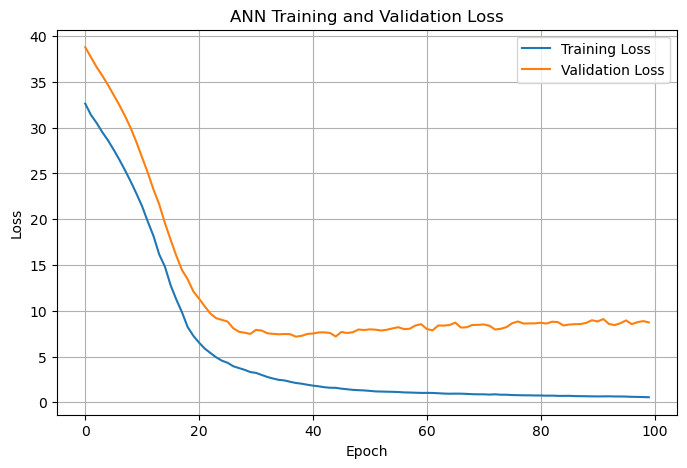

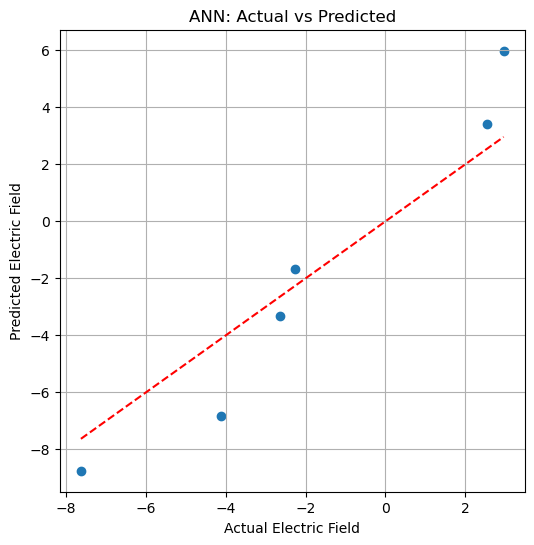

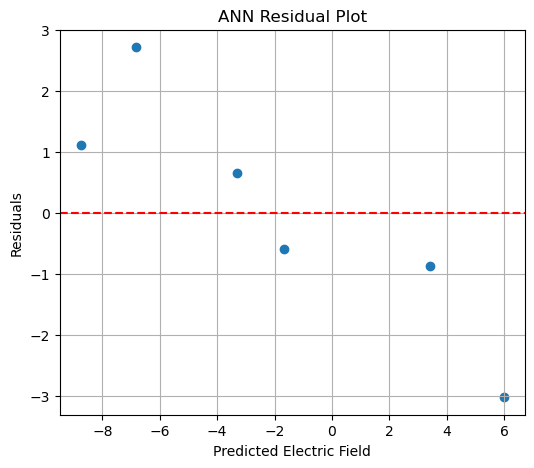

In [11]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Features and Target
X = df[["U", "TR", "IMAX", "I30", "I60", "Distance"]]
y = df["Electric_Field"]

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Build ANN
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1)
])

# Compile Model
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# Train Model
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=4,
    validation_split=0.2,
    verbose=1
)

# Predictions
pred = model.predict(X_test).flatten()

# Evaluation Metrics
rmse = np.sqrt(mean_squared_error(y_test, pred))
mae = mean_absolute_error(y_test, pred)
r2 = r2_score(y_test, pred)

print("=" * 50)
print("Artificial Neural Network")
print("=" * 50)
print("RMSE :", rmse)
print("MAE :", mae)
print("R2 :", r2)

# Model Summary
print("\nModel Summary")
model.summary()

# Loss Curve
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# Actual vs Predicted
plt.figure(figsize=(6,6))
plt.scatter(y_test, pred)
plt.plot(
    [min(y_test), max(y_test)],
    [min(y_test), max(y_test)],
    'r--'
)
plt.xlabel("Actual Electric Field")
plt.ylabel("Predicted Electric Field")
plt.title("ANN: Actual vs Predicted")
plt.grid(True)
plt.show()

# Residual Plot
residuals = y_test - pred

plt.figure(figsize=(6,5))
plt.scatter(pred, residuals)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel("Predicted Electric Field")
plt.ylabel("Residuals")
plt.title("ANN Residual Plot")
plt.grid(True)
plt.show()

Anomaly Detection

DBSCAN Results

Cluster Labels:
Anomaly
 2    14
 1     7
-1     5
 0     4
Name: count, dtype: int64

Original Samples : 30
Outliers Detected : 5
Normal Samples : 25

Detected Outliers
    U    TR   IMAX   I30   I60  Distance  Material  Electric_Field  \
16  4  0.78  14.98  6.97  5.01        50         0            2.80   
17  4  0.79  14.75  6.87  5.09        65         0            2.55   
21 -4  0.73 -15.46 -7.36  5.11        65         2            6.19   
23 -4  0.76 -14.78 -7.24 -5.19        65         0           -4.12   
29 -4  0.76 -14.83 -7.42 -4.99        65         2           -7.41   

    Magnetic_Field  Anomaly  
16            5.14       -1  
17            4.51       -1  
21            2.10       -1  
23           -2.84       -1  
29           -2.20       -1  


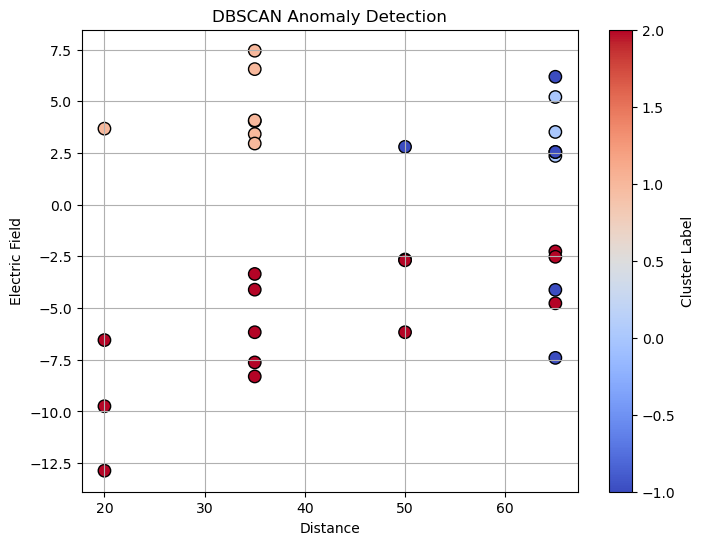


Clean Dataset Shape : (25, 9)

Clean dataset saved as:
ESD_Cleaned_After_DBSCAN.csv

First Five Rows
   U    TR  IMAX   I30   I60  Distance  Material  Electric_Field  \
0  2  0.77  6.95  3.78  2.44        35         0            4.04   
1  2  0.75  7.17  3.69  2.45        65         0            2.36   
2  2  0.76  7.13  3.95  2.50        35         1            3.42   
3  2  0.73  7.28  3.93  2.39        65         1            2.55   
4  2  0.73  7.34  3.67  2.43        35         2            4.08   

   Magnetic_Field  
0            2.03  
1            1.38  
2            1.64  
3            0.95  
4            1.68  


In [9]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

# ===============================
# Select Features
# ===============================

X = df[["U", "TR", "IMAX", "I30", "I60", "Distance"]]

# ===============================
# Standardize Features
# ===============================

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ===============================
# DBSCAN Anomaly Detection
# ===============================

dbscan = DBSCAN(
    eps=1.5,
    min_samples=3
)

labels = dbscan.fit_predict(X_scaled)

# ===============================
# Add Labels to Dataset
# ===============================

df["Anomaly"] = labels

# ===============================
# Display Results
# ===============================

print("="*50)
print("DBSCAN Results")
print("="*50)

print("\nCluster Labels:")
print(df["Anomaly"].value_counts())

print("\nOriginal Samples :", len(df))
print("Outliers Detected :", (df["Anomaly"] == -1).sum())
print("Normal Samples :", (df["Anomaly"] != -1).sum())

# ===============================
# Show Outliers
# ===============================

print("\nDetected Outliers")
print(df[df["Anomaly"] == -1])

# ===============================
# Visualization
# ===============================

plt.figure(figsize=(8,6))

plt.scatter(
    df["Distance"],
    df["Electric_Field"],
    c=df["Anomaly"],
    cmap="coolwarm",
    s=80,
    edgecolors="black"
)

plt.xlabel("Distance")
plt.ylabel("Electric Field")
plt.title("DBSCAN Anomaly Detection")
plt.colorbar(label="Cluster Label")
plt.grid(True)
plt.show()

# ===============================
# Remove Outliers
# ===============================

clean_df = df[df["Anomaly"] != -1].copy()

clean_df.drop(columns=["Anomaly"], inplace=True)

print("\nClean Dataset Shape :", clean_df.shape)

# ===============================
# Save Clean Dataset
# ===============================

clean_df.to_csv("ESD_Cleaned_After_DBSCAN.csv", index=False)

print("\nClean dataset saved as:")
print("ESD_Cleaned_After_DBSCAN.csv")

# ===============================
# Preview Clean Dataset
# ===============================

print("\nFirst Five Rows")
print(clean_df.head())

In [13]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

X = clean_df[["U","TR","IMAX","I30","I60","Distance"]]
y = clean_df["Electric_Field"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

pred = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, pred))
mae = mean_absolute_error(y_test, pred)
r2 = r2_score(y_test, pred)

cv = cross_val_score(model, X, y, cv=5, scoring="r2").mean()

print("="*50)
print("Linear Regression (After DBSCAN)")
print("="*50)
print("RMSE :", rmse)
print("MAE :", mae)
print("R2 :", r2)
print("Cross Validation :", cv)

Linear Regression (After DBSCAN)
RMSE : 1.6415701221505186
MAE : 1.4676548125484694
R2 : 0.8994352156285661
Cross Validation : -5.661470983426718


In [14]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

X = clean_df[["U","TR","IMAX","I30","I60","Distance"]]
y = clean_df["Electric_Field"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = Pipeline([
    ("poly", PolynomialFeatures(degree=2)),
    ("linear", LinearRegression())
])

model.fit(X_train, y_train)

pred = model.predict(X_test)

print("="*50)
print("Polynomial Regression (After DBSCAN)")
print("="*50)
print("RMSE :", np.sqrt(mean_squared_error(y_test,pred)))
print("MAE :", mean_absolute_error(y_test,pred))
print("R2 :", r2_score(y_test,pred))

Polynomial Regression (After DBSCAN)
RMSE : 0.9595381660641794
MAE : 0.8571860640892401
R2 : 0.9656401265145138


In [15]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

X = clean_df[["U","TR","IMAX","I30","I60","Distance"]]
y = clean_df["Electric_Field"]

X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.2,random_state=42
)

param = {
    "max_depth":[3,5,8,10,None],
    "min_samples_split":[2,5,10],
    "min_samples_leaf":[1,2,4]
}

grid = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param,
    cv=5
)

grid.fit(X_train,y_train)

model = grid.best_estimator_

pred = model.predict(X_test)

print("="*50)
print("Decision Tree (After DBSCAN)")
print("="*50)
print("Best Parameters :",grid.best_params_)
print("RMSE :",np.sqrt(mean_squared_error(y_test,pred)))
print("MAE :",mean_absolute_error(y_test,pred))
print("R2 :",r2_score(y_test,pred))

Decision Tree (After DBSCAN)
Best Parameters : {'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
RMSE : 1.0657406814042523
MAE : 0.9392000000000001
R2 : 0.9576132482147458


In [16]:
from sklearn.ensemble import RandomForestRegressor

X = clean_df[["U","TR","IMAX","I30","I60","Distance"]]
y = clean_df["Electric_Field"]

X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.2,random_state=42
)

param = {
    "n_estimators":[50,100,150],
    "max_depth":[5,10,None],
    "min_samples_split":[2,5],
    "min_samples_leaf":[1,2]
}

grid = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param,
    cv=5
)

grid.fit(X_train,y_train)

model = grid.best_estimator_

pred = model.predict(X_test)

print("="*50)
print("Random Forest (After DBSCAN)")
print("="*50)
print("Best Parameters :",grid.best_params_)
print("RMSE :",np.sqrt(mean_squared_error(y_test,pred)))
print("MAE :",mean_absolute_error(y_test,pred))
print("R2 :",r2_score(y_test,pred))

Random Forest (After DBSCAN)
Best Parameters : {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 150}
RMSE : 0.9338068075237906
MAE : 0.7617333333333284
R2 : 0.9674582338374086


In [17]:
from sklearn.ensemble import ExtraTreesRegressor

X = clean_df[["U","TR","IMAX","I30","I60","Distance"]]
y = clean_df["Electric_Field"]

X_train, X_test, y_train, y_test = train_test_split(
    X,y,test_size=0.2,random_state=42
)

param = {
    "n_estimators":[50,100,150],
    "max_depth":[5,10,None],
    "min_samples_split":[2,5],
    "min_samples_leaf":[1,2]
}

grid = GridSearchCV(
    ExtraTreesRegressor(random_state=42),
    param,
    cv=5
)

grid.fit(X_train,y_train)

model = grid.best_estimator_

pred = model.predict(X_test)

print("="*50)
print("Extra Trees (After DBSCAN)")
print("="*50)
print("Best Parameters :",grid.best_params_)
print("RMSE :",np.sqrt(mean_squared_error(y_test,pred)))
print("MAE :",mean_absolute_error(y_test,pred))
print("R2 :",r2_score(y_test,pred))

Extra Trees (After DBSCAN)
Best Parameters : {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
RMSE : 1.4649867223706239
MAE : 1.096816666666664
R2 : 0.9199070249434687


Epoch 1/100


C:\Users\ASUS\AppData\Roaming\Python\Python312\site-packages\keras\src\layers\core\dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 100ms/step - loss: 25.8550 - mae: 4.4334 - val_loss: 54.3400 - val_mae: 6.8917
Epoch 2/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 23.8287 - mae: 4.0548 - val_loss: 53.2387 - val_mae: 6.7671
Epoch 3/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 23.7233 - mae: 4.0696 - val_loss: 52.0707 - val_mae: 6.6339
Epoch 4/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 21.8869 - mae: 3.8288 - val_loss: 50.8476 - val_mae: 6.4790
Epoch 5/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 18.8443 - mae: 3.6816 - val_loss: 49.7041 - val_mae: 6.3103
Epoch 6/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 15.5979 - mae: 3.1930 - val_loss: 48.5966 - val_mae: 6.1449
Epoch 7/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 15.0637 - mae: 3.3318 - val_loss: 47.4829 - val_mae: 5.9579
Epoch 8/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 26.1686 - mae: 3.8869 - val_loss: 46.2944 - val_mae: 5.8546
Epoch 9/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - loss: 12.4174 -

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,221 (36.02 KB)

 Trainable params: 3,073 (12.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,148 (24.02 KB)

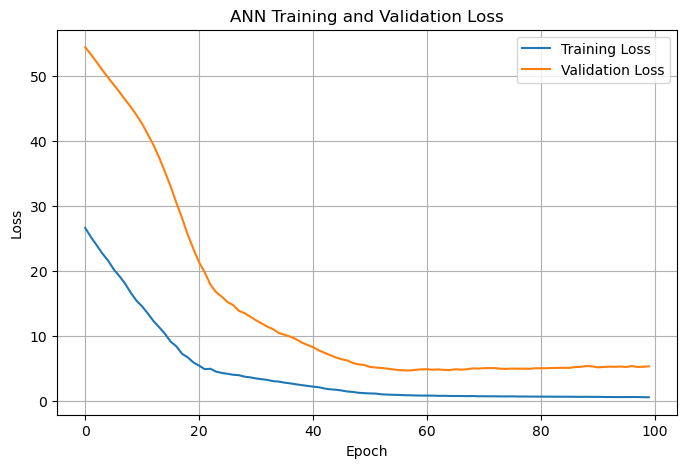

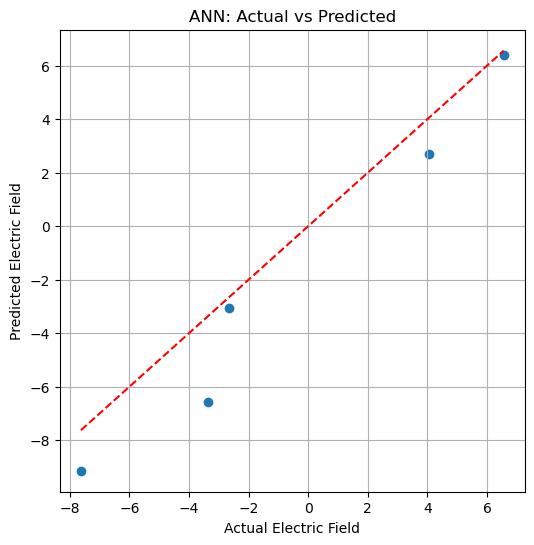

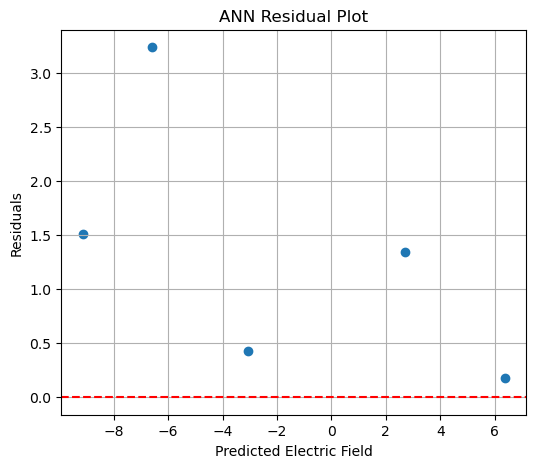

In [18]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Features and Target
X = clean_df[["U","TR","IMAX","I30","I60","Distance"]]
y = clean_df["Electric_Field"]

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Build ANN
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1)
])

# Compile Model
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# Train Model
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=4,
    validation_split=0.2,
    verbose=1
)

# Predictions
pred = model.predict(X_test).flatten()

# Evaluation Metrics
rmse = np.sqrt(mean_squared_error(y_test, pred))
mae = mean_absolute_error(y_test, pred)
r2 = r2_score(y_test, pred)

print("=" * 50)
print("Artificial Neural Network")
print("=" * 50)
print("RMSE :", rmse)
print("MAE :", mae)
print("R2 :", r2)

# Model Summary
print("\nModel Summary")
model.summary()

# Loss Curve
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ANN Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

# Actual vs Predicted
plt.figure(figsize=(6,6))
plt.scatter(y_test, pred)
plt.plot(
    [min(y_test), max(y_test)],
    [min(y_test), max(y_test)],
    'r--'
)
plt.xlabel("Actual Electric Field")
plt.ylabel("Predicted Electric Field")
plt.title("ANN: Actual vs Predicted")
plt.grid(True)
plt.show()

# Residual Plot
residuals = y_test - pred

plt.figure(figsize=(6,5))
plt.scatter(pred, residuals)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel("Predicted Electric Field")
plt.ylabel("Residuals")
plt.title("ANN Residual Plot")
plt.grid(True)
plt.show()

In [1]:
import pandas as pd

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

df = pd.read_csv("ESD_Cleaned.csv")

X = df[["U","TR","IMAX","I30","I60","Distance"]]
y = df["Electric_Field"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()

model.fit(X_train, y_train)

# Store for plotting
lr_pred_before = model.predict(X_test)
y_test_before = y_test

rmse = np.sqrt(mean_squared_error(y_test_before, lr_pred_before))
mae = mean_absolute_error(y_test_before, lr_pred_before)
r2 = r2_score(y_test_before, lr_pred_before)

cv = cross_val_score(model, X, y, cv=5, scoring="r2")

print("="*50)
print("Linear Regression (Before DBSCAN)")
print("="*50)

print("RMSE :", rmse)
print("MAE :", mae)
print("R2 :", r2)
print("Cross Validation :", cv.mean())

Linear Regression (Before DBSCAN)
RMSE : 2.389985402890215
MAE : 1.9032117412817096
R2 : 0.5813577662087948
Cross Validation : -2.773254970653972


In [10]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

X = clean_df[["U","TR","IMAX","I30","I60","Distance"]]
y = clean_df["Electric_Field"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

# Store for plotting
lr_pred_after = model.predict(X_test)
y_test_after = y_test

rmse = np.sqrt(mean_squared_error(y_test_after, lr_pred_after))
mae = mean_absolute_error(y_test_after, lr_pred_after)
r2 = r2_score(y_test_after, lr_pred_after)

cv = cross_val_score(model, X, y, cv=5, scoring="r2").mean()

print("="*50)
print("Linear Regression (After DBSCAN)")
print("="*50)
print("RMSE :", rmse)
print("MAE :", mae)
print("R2 :", r2)
print("Cross Validation :", cv)

Linear Regression (After DBSCAN)
RMSE : 1.6415701221505186
MAE : 1.4676548125484694
R2 : 0.8994352156285661
Cross Validation : -5.661470983426718


Text(0, 0.5, 'Predicted Values')

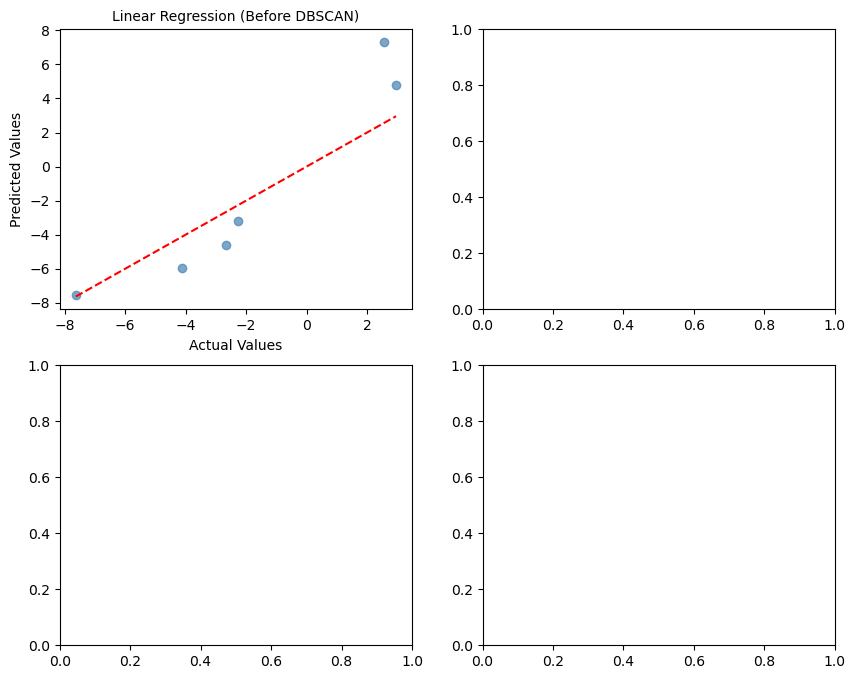

NameError: name 'y_test_after' is not defined

   Actual  Predicted
0   -7.63  -7.564737
1    2.96   4.802938
2   -4.12  -5.968441
3    2.55   7.316971
4   -2.65  -4.616643
5   -2.26  -3.189014


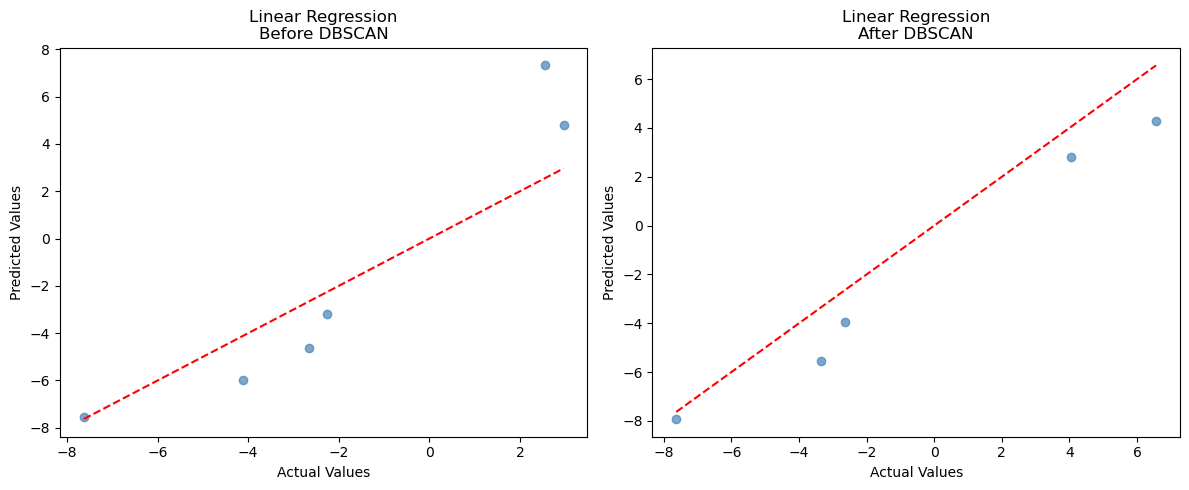

In [11]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# -------- Before DBSCAN --------
axs[0].scatter(y_test_before, lr_pred_before, color='steelblue', alpha=0.7)
axs[0].plot(
    [min(y_test_before), max(y_test_before)],
    [min(y_test_before), max(y_test_before)],
    'r--',
    linewidth=1.5
)
axs[0].set_title("Linear Regression\nBefore DBSCAN")
axs[0].set_xlabel("Actual Values")
axs[0].set_ylabel("Predicted Values")

# -------- After DBSCAN --------
axs[1].scatter(y_test_after, lr_pred_after, color='steelblue', alpha=0.7)
axs[1].plot(
    [min(y_test_after), max(y_test_after)],
    [min(y_test_after), max(y_test_after)],
    'r--',
    linewidth=1.5
)
axs[1].set_title("Linear Regression\nAfter DBSCAN")
axs[1].set_xlabel("Actual Values")
axs[1].set_ylabel("Predicted Values")

plt.tight_layout()

plt.savefig(
    "Linear_Regression_Before_vs_After_DBSCAN.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Decision Tree (Before DBSCAN)
Best Parameters : {'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
RMSE : 1.0657406814042523
MAE : 0.9392000000000001
R2 : 0.9576132482147458


Decision Tree (After DBSCAN)
Best Parameters : {'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
RMSE : 1.0657406814042523
MAE : 0.9392000000000001
R2 : 0.9576132482147458


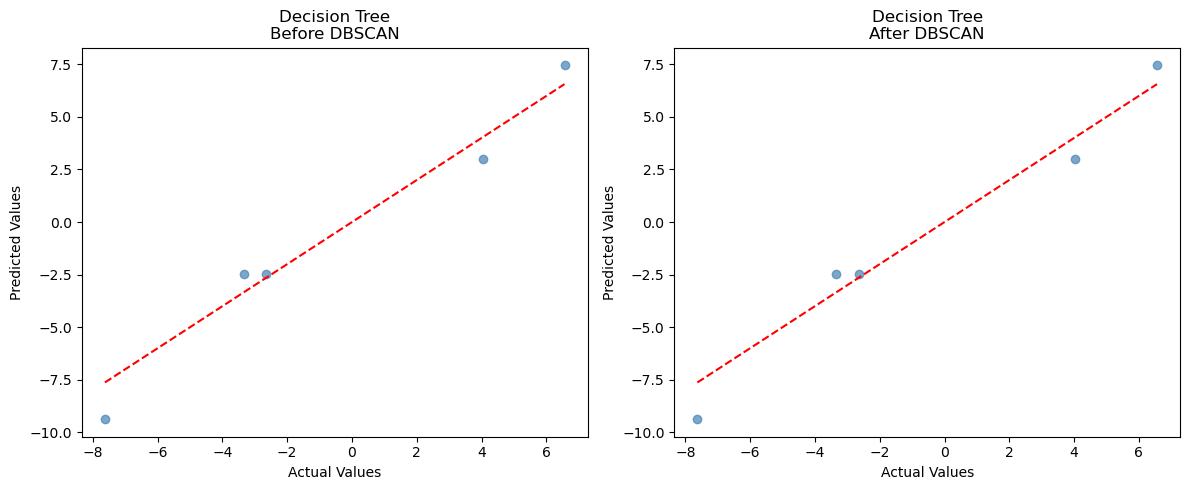